# Lab01 - sprint 2

## Генератор случайных чисел для `n_center`

### Постановка

Цель — построить генератор, который выдаёт значения случайной величины `n_center` (число дефектных чипов в центральной зоне пластины) с теми же статистическими свойствами, что и реальные данные. В спринте 1 мы получили, что дисперсия больше среднего ($s^2/\bar x\approx1.63$) и пуассоновская модель отвергнута. Лучше всего подошло отрицательное биномиальное распределение $\mathrm{NB}(r,p)$, поэтому генератор строим для него. Параметры находим методом моментов.

Готовым `numpy.random.negative_binomial` мы не пользуемся. Весь генератор собран из нескольких классических алгоритмов, и в основе у него один равномерный датчик:

1. **вихрь Мерсенна** даёт $U\sim U(0,1)$;
2. **метод полярных координат** (Марсалья) превращает пары $U$ в нормальные величины;
3. алгоритм **Марсальи–Цанга** (отбор по Нейману со «сжатием») делает из нормальных величин гамма-величину;
4. **метод обратной функции** (последовательный поиск) даёт пуассоновскую величину;
5. **метод суперпозиции**: $\Lambda\sim\mathrm{Gamma}(r,\theta)$, затем $Y\mid\Lambda\sim\mathrm{Poisson}(\Lambda)$, и тогда $Y\sim\mathrm{NB}(r,p)$.

### Подходы из таблицы датчиков

| Подход из таблицы | Роль в генераторе | Статус |
|---|---|---|
| Метод суперпозиции | Основной метод: NB как гамма-смесь пуассоновских распределений | используется |
| Вихрь Мерсенна | Базовый датчик $U\sim U(0,1)$ | используется, своя реализация |
| Метод полярных координат | Нормальные числа для гамма-генератора | используется |
| Метод Неймана (отбора) | Отбор со «сжатием» в алгоритме Марсальи–Цанга | используется |
| Метод обратной функции | Пуассоновская величина | используется |
| Метод псевдонимов (Уокер) | Генерация по таблице вероятностей NB | не реализован, возможное расширение |
| Остальные (показательные, «чёт-нечет», отношений и т. д.) | — | не используются |

### Математическое обоснование

**1. Метод суперпозиции.** Пусть интенсивность $\Lambda\sim\mathrm{Gamma}(r,\theta)$ с плотностью
$$f(\lambda)=\frac{\lambda^{r-1}e^{-\lambda/\theta}}{\Gamma(r)\,\theta^{r}},\quad \lambda>0,$$
а при фиксированном $\Lambda=\lambda$ величина $Y\sim\mathrm{Poisson}(\lambda)$. По формуле полной вероятности
$$P(Y=k)=\int_0^\infty \frac{e^{-\lambda}\lambda^{k}}{k!}\cdot\frac{\lambda^{r-1}e^{-\lambda/\theta}}{\Gamma(r)\theta^{r}}\,d\lambda
=\frac{1}{k!\,\Gamma(r)\,\theta^{r}}\int_0^\infty \lambda^{k+r-1}e^{-\lambda(1+\theta)/\theta}\,d\lambda .$$
Последний интеграл — гамма-функция: $\int_0^\infty\lambda^{m-1}e^{-c\lambda}d\lambda=\Gamma(m)/c^m$ при $m=k+r$, $c=(1+\theta)/\theta$. Получаем
$$P(Y=k)=\frac{\Gamma(k+r)}{k!\,\Gamma(r)\,\theta^{r}}\left(\frac{\theta}{1+\theta}\right)^{k+r}.$$
Подставляем $\theta=(1-p)/p$: тогда $\frac{1}{1+\theta}=p$, $\frac{\theta}{1+\theta}=1-p$, и
$$P(Y=k)=\binom{k+r-1}{k}p^{r}(1-p)^{k},$$
то есть $Y\sim\mathrm{NB}(r,p)$. Моменты считаем по формулам полного математического ожидания и полной дисперсии:
$$\mathrm{E}Y=\mathrm{E}\Lambda=r\theta=\mu,\qquad
\mathrm{Var}\,Y=\mathrm{E}[\mathrm{Var}(Y\mid\Lambda)]+\mathrm{Var}[\mathrm{E}(Y\mid\Lambda)]=\mathrm{E}\Lambda+\mathrm{Var}\Lambda=r\theta+r\theta^{2}=\mu+\frac{\mu^{2}}{r}>\mu.$$
Отсюда понятно, откуда берётся перерассеяние: интенсивность $\Lambda$ случайна (разная дефектность лотов и пластин), и это добавляет к пуассоновской дисперсии слагаемое $\mu^2/r$.

**2. Параметры (метод моментов).** Из $s^{2}/\bar{x}=1+\theta$ получаем
$$\theta=\frac{s^{2}}{\bar{x}}-1,\qquad r=\frac{\bar{x}}{\theta},\qquad p=\frac{1}{1+\theta}=\frac{\bar{x}}{s^{2}}.$$

**3. Равномерный датчик.** Вихрь Мерсенна MT19937 хранит состояние из 624 32-битных слов. Раз в 624 шага состояние целиком пересчитывается линейным рекуррентным преобразованием над $\mathrm{GF}(2)$ («скручивание»), а каждое выдаваемое слово дополнительно перемешивается сдвигами и масками («закалка»). Период $2^{19937}-1$, последовательность равнораспределена в 623 измерениях. Из двух 32-битных слов собираем число $U\in[0,1)$ с 53 значащими битами.

**4. Метод полярных координат (нормальная величина).** Берём $V_1,V_2\sim U(-1,1)$ и принимаем пару, если $S=V_1^2+V_2^2\in(0,1)$. Вероятность принятия равна отношению площадей круга и квадрата, $\pi/4$. Принятая точка равномерна в круге, поэтому $S\sim U(0,1)$, а угол точки от $S$ не зависит, и $\cos\varphi=V_1/\sqrt S$, $\sin\varphi=V_2/\sqrt S$. Подставляем $R^2=-2\ln S$ в преобразование Бокса–Мюллера:
$$X_1=V_1\sqrt{\frac{-2\ln S}{S}},\qquad X_2=V_2\sqrt{\frac{-2\ln S}{S}},$$
и $X_1,X_2\sim N(0,1)$ независимы. Тригонометрические функции не нужны, а за одну принятую пару получаем два числа.

**5. Метод Неймана для гамма-распределения (Марсалья–Цанг, $a\ge1$).** Положим $d=a-\tfrac13$, $c=1/\sqrt{9d}$, возьмём $X\sim N(0,1)$ и $V=(1+cX)^3$. Если подставить $y=dV$ в плотность $g(y)\propto y^{a-1}e^{-y}$ и учесть якобиан $dy/dx=3dc(1+cX)^2$, то плотность $X$ оказывается пропорциональной
$$h(x)\propto V^{\,d}e^{-dV}.$$
В качестве мажоранты берём нормальную плотность $e^{-x^2/2}$: Марсалья и Цанг (2000) показали, что при подходящей нормировке она действительно лежит выше $h$. Нормируем отношение на единицу в точке $x=0$ и принимаем $X$ с вероятностью $h(x)/e^{-x^2/2}$. Получается условие
$$\ln U<\frac{x^2}{2}+d-dV+d\ln V\quad\Rightarrow\quad Y=d\,V\sim\mathrm{Gamma}(a,1).$$
Значения $V\le0$ отбрасываются. «Сжатие»: сначала проверяем дешёвое условие $U<1-0.0331\,x^4$. Если оно выполнено, принимаем без вычисления логарифмов, и так проходит большинство попыток. Умножение на $\theta$ даёт $\mathrm{Gamma}(r,\theta)$. Условие $a=r\ge1$ у нас выполнено ($r\approx36.5$).

**6. Метод обратной функции (пуассоновская величина).** Для дискретной $Y$ с функцией распределения $F$ положим $Y=\min\{k:\,F(k)\ge U\}$. Тогда $P(Y\le k)=P(U\le F(k))=F(k)$, то есть $Y$ имеет нужное распределение. Вероятности считаем рекуррентно:
$$p_0=e^{-\lambda},\qquad p_k=p_{k-1}\frac{\lambda}{k}.$$
Поиск идёт от $k=0$, поэтому в среднем делается $\mathrm{E}Y=\lambda$ шагов. При $\lambda\approx23$ это быстро, а $e^{-\lambda}\approx10^{-10}$ ещё не уходит в машинный ноль.

**Итоговый алгоритм.**
1. $\Lambda\leftarrow\theta\cdot\mathrm{Gamma}(r,1)$ (шаги 3–5).
2. $Y\leftarrow\mathrm{Poisson}(\Lambda)$ методом обратной функции (шаг 6).
3. Вернуть $Y\sim\mathrm{NB}(r,p)$.

### Данные и параметры

In [1]:
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 2026
M_CHECK = 100_000   # объём для проверки самого датчика (известные параметры)

df = pd.read_parquet("../wm811k_features.parquet")
xv = df["n_center"].to_numpy()
N = len(xv)

# метод моментов
x_mean, x_var = xv.mean(), xv.var(ddof=1)
theta = x_var / x_mean - 1          # масштаб гамма-распределения
r_nb = x_mean / theta               # параметр формы, он же n у scipy.stats.nbinom
p_nb = x_mean / x_var
pd.Series({"N": N, "среднее": x_mean, "дисперсия": x_var, "s^2 / x": x_var / x_mean,
           "theta": theta, "r": r_nb, "p": p_nb,
           "проверка: (1 - p) / p = theta": (1 - p_nb) / p_nb}).round(5)

N                                15881.00000
среднее                             22.96480
дисперсия                           37.41180
s^2 / x                              1.62909
theta                                0.62909
r                                   36.50462
p                                    0.61384
проверка: (1 - p) / p = theta        0.62909
dtype: float64

### Реализация

Ниже две ячейки. В первой — класс `MT19937`, вихрь Мерсенна по описанию авторов: инициализация состояния, скручивание, закалка, 53-битное $U$. Чтобы проверить, что реализация правильная, сравниваем её с эталонным MT19937 из `numpy.random.RandomState` при тех же seed: последовательности должны совпасть бит в бит. Во второй ячейке — класс `NBGenerator`, где каждый метод соответствует одному шагу алгоритма. Генератор считает, сколько равномерных чисел, попыток и шагов поиска он потратил, чтобы потом сравнить это с теорией.

In [2]:
class MT19937:
    """Вихрь Мерсенна MT19937 (Matsumoto, Nishimura, 1998): равномерный датчик."""
    N, M = 624, 397
    MATRIX_A, UPPER, LOWER = 0x9908B0DF, 0x80000000, 0x7FFFFFFF

    def __init__(self, seed=5489):
        mt = [0] * self.N
        mt[0] = seed & 0xFFFFFFFF
        for i in range(1, self.N):
            mt[i] = (1812433253 * (mt[i - 1] ^ (mt[i - 1] >> 30)) + i) & 0xFFFFFFFF
        self.mt, self.idx = mt, self.N

    def _twist(self):
        """Пересчёт всего состояния из 624 слов."""
        mt = self.mt
        for i in range(self.N):
            y = (mt[i] & self.UPPER) | (mt[(i + 1) % self.N] & self.LOWER)
            mt[i] = mt[(i + self.M) % self.N] ^ (y >> 1) ^ (self.MATRIX_A if y & 1 else 0)
        self.idx = 0

    def next_u32(self):
        """Очередное 32-битное слово после «закалки» (tempering)."""
        if self.idx >= self.N:
            self._twist()
        y = self.mt[self.idx]
        self.idx += 1
        y ^= y >> 11
        y ^= (y << 7) & 0x9D2C5680
        y ^= (y << 15) & 0xEFC60000
        y ^= y >> 18
        return y

    def random(self):
        """U[0, 1) с 53 значащими битами (как genrand_res53)."""
        a, b = self.next_u32() >> 5, self.next_u32() >> 6
        return (a * 67108864.0 + b) / 9007199254740992.0


# проверка реализации: та же последовательность, что у эталонного MT19937 в numpy
for s in [5489, 42, SEED]:
    mine = MT19937(s)
    same = np.array_equal([mine.random() for _ in range(5000)], np.random.RandomState(s).random_sample(5000))
    print(f"seed = {s}: первые 5000 чисел совпадают с numpy.random.RandomState: {same}")

seed = 5489: первые 5000 чисел совпадают с numpy.random.RandomState: True
seed = 42: первые 5000 чисел совпадают с numpy.random.RandomState: True
seed = 2026: первые 5000 чисел совпадают с numpy.random.RandomState: True


In [3]:
class NBGenerator:
    """NB(r, p) как гамма-смесь Пуассона. Всё строится только на MT19937."""

    def __init__(self, r, p, seed=SEED):
        self.r, self.p = r, p
        self.theta = (1 - p) / p
        self.u = MT19937(seed)
        self._spare = None                      # второе нормальное число из пары
        self.count = {"U": 0, "пар полярного метода": 0, "принятых пар": 0,
                      "гамма: попыток": 0, "гамма: принято сжатием": 0, "гамма: принято": 0,
                      "Пуассон: шагов поиска": 0, "Пуассон: вызовов": 0}

    def uniform(self):
        self.count["U"] += 1
        return self.u.random()

    def normal(self):
        """Полярный метод Марсальи: две N(0, 1) из точки, равномерной в круге."""
        if self._spare is not None:
            z, self._spare = self._spare, None
            return z
        while True:
            self.count["пар полярного метода"] += 1
            v1, v2 = 2 * self.uniform() - 1, 2 * self.uniform() - 1
            s = v1 * v1 + v2 * v2
            if 0 < s < 1:
                break
        self.count["принятых пар"] += 1
        k = math.sqrt(-2 * math.log(s) / s)
        self._spare = v2 * k
        return v1 * k

    def gamma(self, a):
        """Марсалья-Цанг (a >= 1): отбор по Нейману со сжатием, Gamma(a, 1)."""
        d = a - 1 / 3
        c = 1 / math.sqrt(9 * d)
        while True:
            self.count["гамма: попыток"] += 1
            x = self.normal()
            v = 1 + c * x
            if v <= 0:
                continue
            v = v ** 3
            u = self.uniform()
            if u < 1 - 0.0331 * x ** 4:        # сжатие: быстрое принятие без логарифмов
                self.count["гамма: принято сжатием"] += 1
                self.count["гамма: принято"] += 1
                return d * v
            if u > 0 and math.log(u) < 0.5 * x * x + d * (1 - v + math.log(v)):
                self.count["гамма: принято"] += 1
                return d * v

    def poisson(self, lam):
        """Обратная функция: последовательный поиск min{k: F(k) >= U}."""
        self.count["Пуассон: вызовов"] += 1
        u = self.uniform()
        k, pk = 0, math.exp(-lam)
        F = pk
        while F < u:
            k += 1
            pk *= lam / k
            F += pk
            self.count["Пуассон: шагов поиска"] += 1
        return k

    def nb(self):
        """Суперпозиция: Lambda ~ Gamma(r, theta), затем Y | Lambda ~ Poisson(Lambda)."""
        lam = self.theta * self.gamma(self.r)
        return self.poisson(lam)

    def sample(self, n):
        return np.array([self.nb() for _ in range(n)])

### Проверка звеньев датчика

Прежде чем проверять итоговое распределение, проверяем каждое звено отдельно. Для каждого звена теоретический закон известен **полностью** (параметры не оцениваются по выборке), поэтому обычный KS здесь корректен. Берём по 50 000 значений. Дополнительно сравниваем доли принятых попыток с теорией: для полярного метода $\pi/4$, для Пуассона среднее число шагов поиска $\lambda$.

In [4]:
chk = NBGenerator(r_nb, p_nb, seed=1)
K = 50_000
u = np.array([chk.uniform() for _ in range(K)])
z = np.array([chk.normal() for _ in range(K)])
g = np.array([chk.gamma(r_nb) for _ in range(K)])
lam_test = x_mean
po = np.array([chk.poisson(lam_test) for _ in range(K)])

def chi2_discrete(sample, pmf, kmin, kmax):
    """chi2 согласия с известным дискретным законом, хвосты объединены в крайние бины."""
    ks = np.arange(kmin, kmax + 1)
    probs = pmf(ks)
    probs[0] += pmf(np.arange(0, kmin)).sum() if kmin > 0 else 0
    probs[-1] = 1 - probs[:-1].sum()
    O = np.array([(np.clip(sample, kmin, kmax) == k).sum() for k in ks])
    return stats.chisquare(O, len(sample) * probs)

u_bins = np.histogram(u, bins=20, range=(0, 1))[0]
checks = pd.DataFrame({
    "U(0,1)": {"теор. среднее": 0.5, "выб. среднее": u.mean(), "теор. дисперсия": 1 / 12,
               "выб. дисперсия": u.var(ddof=1),
               "критерий": "chi2, 20 равных интервалов", "p-value": stats.chisquare(u_bins).pvalue},
    "N(0,1), полярный": {"теор. среднее": 0, "выб. среднее": z.mean(), "теор. дисперсия": 1,
                         "выб. дисперсия": z.var(ddof=1),
                         "критерий": "KS, параметры известны", "p-value": stats.kstest(z, "norm").pvalue},
    "Gamma(r, 1), Марсалья-Цанг": {"теор. среднее": r_nb, "выб. среднее": g.mean(), "теор. дисперсия": r_nb,
                                    "выб. дисперсия": g.var(ddof=1), "критерий": "KS, параметры известны",
                                    "p-value": stats.kstest(g, "gamma", args=(r_nb,)).pvalue},
    f"Poisson({lam_test:.2f}), обратная функция": {
        "теор. среднее": lam_test, "выб. среднее": po.mean(), "теор. дисперсия": lam_test,
        "выб. дисперсия": po.var(ddof=1), "критерий": "chi2, хвосты объединены",
        "p-value": chi2_discrete(po, lambda k: stats.poisson.pmf(k, lam_test), 10, 37).pvalue},
}).T
# последовательная независимость U: корреляция соседних значений
print(f"корреляция U_i и U_(i+1): {np.corrcoef(u[:-1], u[1:])[0, 1]:.5f} (при независимости ~ N(0, 1/K), sd = {1 / np.sqrt(K):.5f})")
checks

корреляция U_i и U_(i+1): -0.00276 (при независимости ~ N(0, 1/K), sd = 0.00447)


,теор. среднее,выб. среднее,теор. дисперсия,выб. дисперсия,критерий,p-value
"U(0,1)",0.5,0.499329,0.083333,0.083663,"chi2, 20 равных интервалов",0.739222
"N(0,1), полярный",0,0.000525,1,0.996014,"KS, параметры известны",0.824157
"Gamma(r, 1), Марсалья-Цанг",36.504619,36.51379,36.504619,36.400071,"KS, параметры известны",0.779046
"Poisson(22.96), обратная функция",22.964801,22.97256,22.964801,22.972707,"chi2, хвосты объединены",0.07521


In [5]:
cnt = chk.count
pd.Series({
    "полярный метод: доля принятых пар": cnt["принятых пар"] / cnt["пар полярного метода"],
    "теория: pi / 4": math.pi / 4,
    "Марсалья-Цанг: доля принятых попыток": cnt["гамма: принято"] / cnt["гамма: попыток"],
    "из принятых: доля через сжатие": cnt["гамма: принято сжатием"] / cnt["гамма: принято"],
    "Пуассон: среднее число шагов поиска": cnt["Пуассон: шагов поиска"] / cnt["Пуассон: вызовов"],
    "теория: E[Y] = lambda": lam_test,
}).round(4)

полярный метод: доля принятых пар        0.7874
теория: pi / 4                           0.7854
Марсалья-Цанг: доля принятых попыток     0.9991
из принятых: доля через сжатие           0.9188
Пуассон: среднее число шагов поиска     22.9726
теория: E[Y] = lambda                   22.9648
dtype: float64

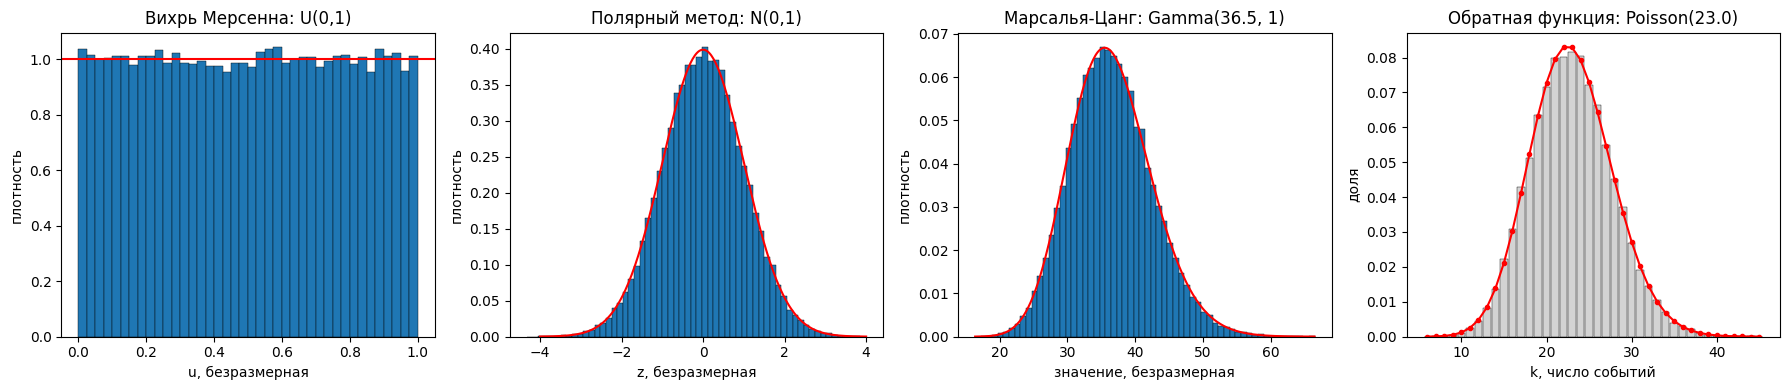

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].hist(u, bins=40, density=True, edgecolor="k", linewidth=0.3)
axes[0].axhline(1, color="r")
axes[0].set_title("Вихрь Мерсенна: U(0,1)")
axes[0].set_xlabel("u, безразмерная")
axes[0].set_ylabel("плотность")

zz = np.linspace(-4, 4, 300)
axes[1].hist(z, bins=60, density=True, edgecolor="k", linewidth=0.3)
axes[1].plot(zz, stats.norm.pdf(zz), "r")
axes[1].set_title("Полярный метод: N(0,1)")
axes[1].set_xlabel("z, безразмерная")
axes[1].set_ylabel("плотность")

gg = np.linspace(g.min(), g.max(), 300)
axes[2].hist(g, bins=60, density=True, edgecolor="k", linewidth=0.3)
axes[2].plot(gg, stats.gamma.pdf(gg, r_nb), "r")
axes[2].set_title(f"Марсалья-Цанг: Gamma({r_nb:.1f}, 1)")
axes[2].set_xlabel("значение, безразмерная")
axes[2].set_ylabel("плотность")

kk = np.arange(po.min(), po.max() + 1)
axes[3].bar(kk, np.bincount(po)[kk] / K, width=0.9, color="lightgray", edgecolor="k", linewidth=0.3)
axes[3].plot(kk, stats.poisson.pmf(kk, lam_test), "ro-", ms=3)
axes[3].set_title(f"Обратная функция: Poisson({lam_test:.1f})")
axes[3].set_xlabel("k, число событий")
axes[3].set_ylabel("доля")
plt.tight_layout()
plt.show()

### Проверка самого генератора NB

Здесь отвечаем на вопрос «правильно ли работает генератор», отдельно от вопроса «похожи ли данные на NB». Генерируем $M=100\,000$ значений и проверяем χ²-критерием согласие с $\mathrm{NB}(r,p)$ при **заданных** $r,p$ (ddof = 0, соседние значения объединены до $E\ge5$).

In [7]:
gen_big = NBGenerator(r_nb, p_nb, seed=SEED + 1)
t0 = time.perf_counter()
ys_big = gen_big.sample(M_CHECK)
t_big = time.perf_counter() - t0
print(f"{M_CHECK} значений за {t_big:.1f} с ({t_big / M_CHECK * 1e6:.0f} мкс на значение), "
      f"U на одно значение: {gen_big.count['U'] / M_CHECK:.2f}")

def merged_bins(probs_fn, n, kmax):
    """Бины 0..kmax, хвост >= kmax; соседние объединяются, пока E < 5."""
    pk = probs_fn(np.arange(kmax))
    probs = np.append(pk, 1 - pk.sum())
    groups, cur, acc = [], [], 0.0
    for i, e in enumerate(n * probs):
        cur.append(i)
        acc += e
        if acc >= 5:
            groups.append(cur)
            cur, acc = [], 0.0
    if cur:
        groups[-1] += cur
    return groups, np.array([probs[g].sum() for g in groups])

kmax = 80
groups, probs = merged_bins(lambda k: stats.nbinom.pmf(k, r_nb, p_nb), M_CHECK, kmax)
cnt_big = np.bincount(np.minimum(ys_big, kmax), minlength=kmax + 1)
O_big = np.array([cnt_big[g].sum() for g in groups])
gof_self = stats.chisquare(O_big, M_CHECK * probs)       # параметры заданы, ddof = 0
print(f"chi2 согласия генератора с NB(r, p): chi2 = {gof_self.statistic:.2f}, df = {len(groups) - 1}, "
      f"p = {gof_self.pvalue:.4f}")
pd.DataFrame({"теория NB(r, p)": [stats.nbinom.mean(r_nb, p_nb), stats.nbinom.var(r_nb, p_nb),
                                 stats.nbinom.stats(r_nb, p_nb, moments="s"), stats.nbinom.stats(r_nb, p_nb, moments="k")],
              f"генератор, M = {M_CHECK}": [ys_big.mean(), ys_big.var(ddof=1), stats.skew(ys_big), stats.kurtosis(ys_big)]},
             index=["среднее", "дисперсия", "асимметрия", "эксцесс"]).astype(float).round(4)

100000 значений за 2.1 с (21 мкс на значение), U на одно значение: 3.27
chi2 согласия генератора с NB(r, p): chi2 = 38.76, df = 46, p = 0.7665


,"теория NB(r, p)","генератор, M = 100000"
среднее,22.9648,23.0003
дисперсия,37.4118,37.5727
асимметрия,0.3692,0.3499
эксцесс,0.1911,0.1541


### 3.1. Сравнение метрик реальных данных и генератора

Генерируем столько же значений, сколько пластин в данных ($N=15881$), и сравниваем метрики: среднее, дисперсию, индекс дисперсии, асимметрию, эксцесс, квантили, долю нулей. Отдельной колонкой даны теоретические значения $\mathrm{NB}(r,p)$.

Разница «генератор − данные» сама по себе ничего не говорит: даже идеальный генератор при $N=15881$ немного отклоняется от теории. Поэтому строим полосу случайного разброса. 200 раз генерируем выборку объёма $N$ из $\mathrm{NB}(r,p)$ (для скорости здесь эталонным `numpy`) и смотрим, попадают ли метрики данных и нашего генератора в 95% полосу.

Формальные проверки «данные против генератора»:
- **χ² однородности** — таблица «источник × значение», крайние значения объединены, все $E\ge5$. $H_0$: обе выборки из одного распределения;
- **Манн–Уитни** — нет ли сдвига; эффект $U/(n_1n_2)$, при отсутствии сдвига 0.5;
- **KS двух выборок** — для дискретных данных консервативен (p-value завышены), поэтому основной критерий — χ²;
- **Левене по медиане** (Браун–Форсайт) — одинаков ли разброс.

Уровень значимости $\alpha=0.05$.

In [8]:
gen = NBGenerator(r_nb, p_nb, seed=SEED)
xs = gen.sample(N)

def metrics(a):
    a = np.asarray(a)
    return pd.Series({"n": len(a), "среднее": a.mean(), "дисперсия": a.var(ddof=1),
                      "D = var / mean": a.var(ddof=1) / a.mean(), "ст. отклонение": a.std(ddof=1),
                      "асимметрия": stats.skew(a), "эксцесс (избыточный)": stats.kurtosis(a),
                      "min": a.min(), "q05": np.quantile(a, 0.05), "q25": np.quantile(a, 0.25),
                      "медиана": np.median(a), "q75": np.quantile(a, 0.75), "q95": np.quantile(a, 0.95),
                      "max": a.max(), "доля нулей": (a == 0).mean()})

theory = pd.Series({"n": np.nan, "среднее": stats.nbinom.mean(r_nb, p_nb), "дисперсия": stats.nbinom.var(r_nb, p_nb),
                    "D = var / mean": 1 / p_nb, "ст. отклонение": stats.nbinom.std(r_nb, p_nb),
                    "асимметрия": float(stats.nbinom.stats(r_nb, p_nb, moments="s")),
                    "эксцесс (избыточный)": float(stats.nbinom.stats(r_nb, p_nb, moments="k")),
                    "min": np.nan, "q05": stats.nbinom.ppf(0.05, r_nb, p_nb), "q25": stats.nbinom.ppf(0.25, r_nb, p_nb),
                    "медиана": stats.nbinom.median(r_nb, p_nb), "q75": stats.nbinom.ppf(0.75, r_nb, p_nb),
                    "q95": stats.nbinom.ppf(0.95, r_nb, p_nb), "max": np.nan, "доля нулей": p_nb ** r_nb})
cmp = pd.DataFrame({"реальные данные": metrics(xv), "генератор": metrics(xs), "теория NB(r, p)": theory})
cmp["генератор - данные"] = cmp["генератор"] - cmp["реальные данные"]
cmp.round(4)

,реальные данные,генератор,"теория NB(r, p)",генератор - данные
n,15881.0000,15881.0000,NaN,0.0000
среднее,22.9648,22.9752,22.9648,0.0104
дисперсия,37.4118,37.8146,37.4118,0.4028
D = var / mean,1.6291,1.6459,1.6291,0.0168
ст. отклонение,6.1165,6.1494,6.1165,0.0328
асимметрия,0.4436,0.3495,0.3692,-0.0941
эксцесс (избыточный),0.4609,0.1662,0.1911,-0.2947
min,5.0000,5.0000,NaN,0.0000
q05,14.0000,13.0000,14.0000,-1.0000
q25,19.0000,19.0000,19.0000,0.0000


In [9]:
# разброс метрик самого генератора: 200 повторов по N значений (векторно, numpy NB с теми же r, p)
# нужен, чтобы понять, укладывается ли разница "генератор - данные" в случайные колебания
ref = np.random.default_rng(SEED)
reps = np.array([[s.mean(), s.var(ddof=1), stats.skew(s), stats.kurtosis(s), np.quantile(s, 0.95)]
                 for s in (ref.negative_binomial(r_nb, p_nb, N) for _ in range(200))])
names = ["среднее", "дисперсия", "асимметрия", "эксцесс (избыточный)", "q95"]
band = pd.DataFrame({"данные": [cmp.loc[n, "реальные данные"] for n in names],
                     "генератор": [cmp.loc[n, "генератор"] for n in names],
                     "NB: q2.5": np.quantile(reps, 0.025, axis=0),
                     "NB: q97.5": np.quantile(reps, 0.975, axis=0)}, index=names)
band["данные в 95% полосе"] = (band["данные"] >= band["NB: q2.5"]) & (band["данные"] <= band["NB: q97.5"])
band["генератор в 95% полосе"] = (band["генератор"] >= band["NB: q2.5"]) & (band["генератор"] <= band["NB: q97.5"])
band.round(4)

,данные,генератор,NB: q2.5,NB: q97.5,данные в 95% полосе,генератор в 95% полосе
среднее,22.9648,22.9752,22.8642,23.0479,True,True
дисперсия,37.4118,37.8146,36.5286,38.0637,True,True
асимметрия,0.4436,0.3495,0.3261,0.4069,False,True
эксцесс (избыточный),0.4609,0.1662,0.0723,0.3088,False,True
q95,33.0000,34.0000,33.0000,34.0000,True,True


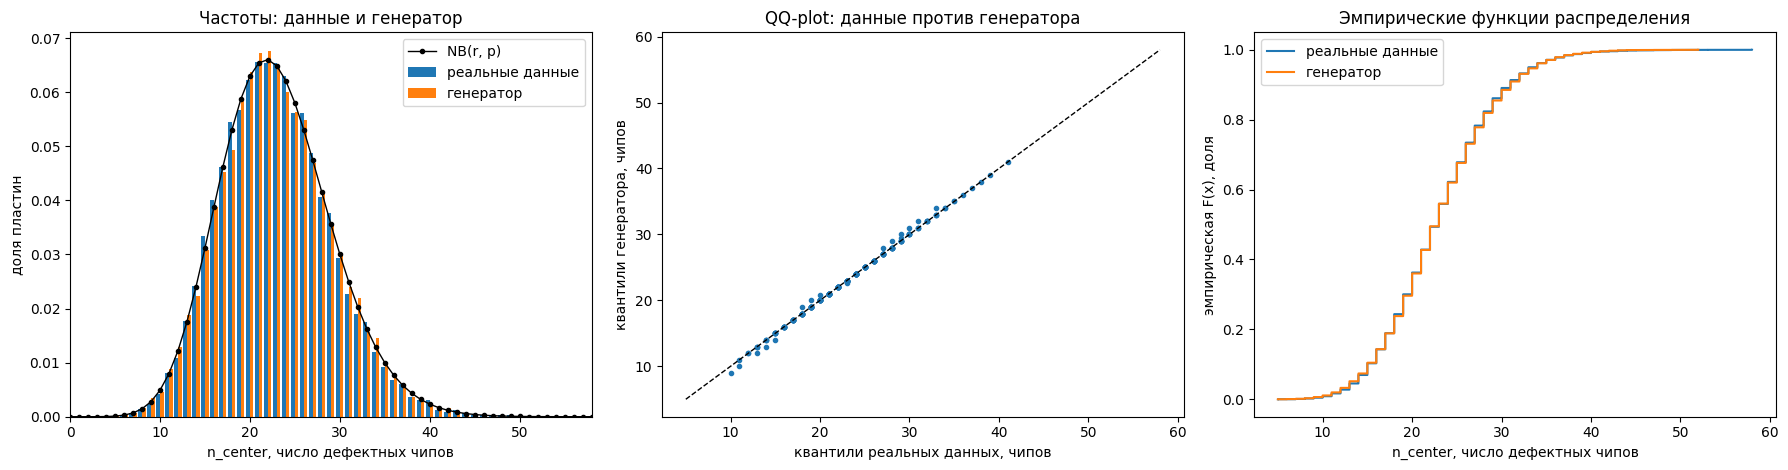

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ks = np.arange(0, max(xv.max(), xs.max()) + 1)
axes[0].bar(ks - 0.2, np.bincount(xv, minlength=len(ks)) / N, width=0.4, label="реальные данные")
axes[0].bar(ks + 0.2, np.bincount(xs, minlength=len(ks)) / N, width=0.4, label="генератор")
axes[0].plot(ks, stats.nbinom.pmf(ks, r_nb, p_nb), "k.-", lw=1, label="NB(r, p)")
axes[0].set_xlim(0, ks.max())
axes[0].set_xlabel("n_center, число дефектных чипов")
axes[0].set_ylabel("доля пластин")
axes[0].set_title("Частоты: данные и генератор")
axes[0].legend()

q = np.linspace(0.005, 0.995, 199)
axes[1].plot(np.quantile(xv, q), np.quantile(xs, q), "o", ms=3)
lim = [xv.min(), xv.max()]
axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set_xlabel("квантили реальных данных, чипов")
axes[1].set_ylabel("квантили генератора, чипов")
axes[1].set_title("QQ-plot: данные против генератора")

for a, lab in [(xv, "реальные данные"), (xs, "генератор")]:
    axes[2].step(np.sort(a), np.arange(1, N + 1) / N, where="post", label=lab)
axes[2].set_xlabel("n_center, число дефектных чипов")
axes[2].set_ylabel("эмпирическая F(x), доля")
axes[2].set_title("Эмпирические функции распределения")
axes[2].legend()
plt.tight_layout()
plt.show()

In [11]:
# chi2 однородности: данные и генератор в одной таблице, крайние значения объединены (все E >= 5)
lo, hi = 8, 42
cat = lambda a: np.clip(a, lo, hi)
tab = pd.crosstab(np.r_[np.zeros(N), np.ones(N)], np.r_[cat(xv), cat(xs)])
chi2_h, p_h, dof_h, E_h = stats.chi2_contingency(tab)
mw = stats.mannwhitneyu(xv, xs, alternative="two-sided", method="asymptotic")
ks2 = stats.ks_2samp(xv, xs)
lev = stats.levene(xv, xs, center="median")
tests = pd.DataFrame({
    "что сравнивает": ["распределение целиком", "сдвиг (P(X>Y) = 1/2)", "распределение целиком",
                       "разброс (Браун-Форсайт)"],
    "статистика": [chi2_h, mw.statistic / N**2, ks2.statistic, lev.statistic],
    "p-value": [p_h, mw.pvalue, ks2.pvalue, lev.pvalue],
}, index=[f"chi2 однородности (df = {dof_h}, min E = {E_h.min():.1f})", "Манн-Уитни, U/(n1 n2)",
          "KS двух выборок (консервативен)", "Левене по медиане"])
tests

,что сравнивает,статистика,p-value
"chi2 однородности (df = 34, min E = 22.5)",распределение целиком,34.175800,0.459297
"Манн-Уитни, U/(n1 n2)",сдвиг (P(X>Y) = 1/2),0.498549,0.653788
KS двух выборок (консервативен),распределение целиком,0.006360,0.902984
Левене по медиане,разброс (Браун-Форсайт),0.797787,0.371763


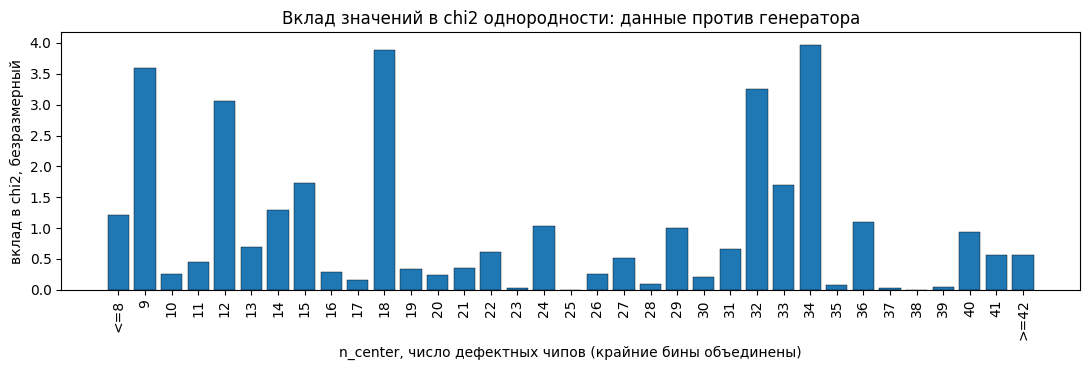

,данные,генератор,вклад в chi2
34,191,232,3.97
18,864,784,3.88
9,36,54,3.60
32,302,348,3.26
12,172,206,3.06
15,531,489,1.73


In [12]:
# где именно расходятся данные и генератор: вклад бинов в chi2
contrib = ((tab - E_h) ** 2 / E_h).sum(axis=0)
lab = [f"<={lo}" if k == lo else (f">={hi}" if k == hi else str(k)) for k in tab.columns]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(lab, contrib.values, edgecolor="k", linewidth=0.3)
ax.set_xlabel("n_center, число дефектных чипов (крайние бины объединены)")
ax.set_ylabel("вклад в chi2, безразмерный")
ax.set_title("Вклад значений в chi2 однородности: данные против генератора")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()
pd.DataFrame({"данные": tab.iloc[0].values, "генератор": tab.iloc[1].values, "вклад в chi2": contrib.values.round(2)},
             index=lab).sort_values("вклад в chi2", ascending=False).head(6)

### Результаты сравнения

**Звенья генератора работают правильно.**
- Наш MT19937 выдаёт ту же последовательность, что эталонный MT19937 в numpy: первые 5000 чисел совпадают для трёх разных seed.
- $U$: среднее 0.4993, дисперсия 0.0837 (теория 0.5 и $1/12=0.0833$), χ² по 20 интервалам $p=0.74$. Корреляция соседних значений $-0.003$ при стандартной ошибке 0.0045, то есть зависимости между соседними числами не видно.
- Полярный метод: KS против $N(0,1)$ $p=0.82$, доля принятых пар 0.787 против $\pi/4=0.785$.
- Марсалья–Цанг: среднее 36.51 и дисперсия 36.40 (теория обе $r=36.50$), KS против $\mathrm{Gamma}(r,1)$ $p=0.78$. Принимается 99.9% попыток, из них 92% сразу по «сжатию», без логарифмов. Поэтому метод такой быстрый.
- Обратная функция: χ² против $\mathrm{Poisson}(22.96)$ $p=0.075$, среднее число шагов поиска 22.97, ровно $\lambda$, как и должно быть.

**Генератор NB правильный.** На 100 000 значениях χ² согласия с $\mathrm{NB}(r,p)$: $\chi^2=38.8$, $df=46$, $p=0.77$. Среднее, дисперсия, асимметрия и эксцесс совпадают с теоретическими. Одно значение стоит в среднем 3.27 равномерных числа и ~20 мкс (чистый Python).

**Сравнение с реальными данными.**
- Среднее 22.98 против 22.96, дисперсия 37.8 против 37.4, индекс дисперсии 1.65 против 1.63. Медиана и квартили совпадают точно, 5% и 95% квантили отличаются на 1 чип.
- Ни один критерий не отличает данные от генератора: χ² однородности $p=0.46$, Манн–Уитни $p=0.65$ (эффект 0.499), KS $p=0.90$, Левене $p=0.37$.
- По χ²-вкладам нет одного «плохого» значения: самые большие вклады (около 4) разбросаны по разным $k$ (9, 12, 18, 32, 34), это обычный случайный шум.

**Где генератор не повторяет данные.** Асимметрия данных 0.44 и эксцесс 0.46, а у NB с нашими параметрами 0.37 и 0.19. Метрики данных **выходят** из 95% полосы NB, а метрики генератора в неё попадают. Максимум в данных 58, у генератора 52. Это не ошибка генератора, а свойство модели: в спринте 1 мы видели, что у данных правый хвост тяжелее, чем у NB (бин «≥48»: 16 пластин вместо 5.7). В χ² однородности хвост объединён в бин «≥42», поэтому критерий этого почти не замечает. Асимметрия и эксцесс сильно зависят от нескольких крайних значений, поэтому они это различие видят.

### Выводы

1. Построен генератор `n_center` на основе отрицательного биномиального распределения $\mathrm{NB}(r=36.50,\ p=0.614)$ с параметрами по методу моментов. Генератор собран из пяти методов: вихрь Мерсенна → полярный метод → Марсалья–Цанг (метод Неймана со сжатием) → обратная функция → суперпозиция (гамма-смесь Пуассона).
2. Каждое звено проверено отдельно: собственный вихрь Мерсенна совпадает с эталоном бит в бит, нормальное, гамма- и пуассоновское распределения проходят критерии согласия, доли принятия совпадают с теорией.
3. Генератор действительно выдаёт $\mathrm{NB}(r,p)$ ($p=0.77$ на 100 000 значений).
4. **Метрики генератора совпадают с метриками реальных данных** по среднему, дисперсии, индексу дисперсии и квантилям. χ² однородности, Манн–Уитни, KS и Левене различий не находят (все $p>0.37$).
5. Не совпадают асимметрия и эксцесс: в данных правый хвост тяжелее, чем у NB. Это ограничение выбранной модели, а не генератора. Возможные улучшения: (а) генерировать по эмпирической таблице вероятностей методом псевдонимов Уокера, тогда хвост повторится точно, но генератор будет просто копировать выборку; (б) взять смесь NB с небольшой второй компонентой для пластин с аномально большим числом дефектов в центре.
6. Физический смысл суперпозиции совпадает с выводами спринта 1: сначала разыгрывается «уровень загрязнения» пластины $\Lambda$ (разный у лотов и пластин), затем при этом уровне дефекты в центре появляются как пуассоновский поток.

### Литература

1. Devroye L. Non-Uniform Random Variate Generation. — New York: Springer, 1986 (метод суперпозиции, обратная функция, генерация отрицательного биномиального как гамма-смеси Пуассона). Обзорная глава автора: https://luc.devroye.org/handbooksimulation1.pdf
2. Matsumoto M., Nishimura T. Mersenne Twister: A 623-Dimensionally Equidistributed Uniform Pseudo-Random Number Generator // ACM Trans. Model. Comput. Simul. 1998. Vol. 8, № 1. P. 3–30. doi:10.1145/272991.272995
3. Marsaglia G., Tsang W. W. A Simple Method for Generating Gamma Variables // ACM Trans. Math. Softw. 2000. Vol. 26, № 3. P. 363–372. doi:10.1145/358407.358414
4. Marsaglia G., Bray T. A. A Convenient Method for Generating Normal Variables // SIAM Review. 1964. Vol. 6, № 3. P. 260–264 (полярный метод).
5. Knuth D. E. The Art of Computer Programming. Vol. 2: Seminumerical Algorithms. 3rd ed. — Addison-Wesley, 1997 (§3.4.1: полярный метод, обратная функция, метод псевдонимов).
6. Walker A. J. An Efficient Method for Generating Discrete Random Variables with General Distributions // ACM Trans. Math. Softw. 1977. Vol. 3, № 3. P. 253–256. doi:10.1145/355744.355749
7. Vose M. D. A Linear Algorithm for Generating Random Numbers with a Given Distribution // IEEE Trans. Softw. Eng. 1991. Vol. 17, № 9. P. 972–975. doi:10.1109/32.92917
8. Hörmann W., Leydold J., Derflinger G. Automatic Nonuniform Random Variate Generation. — Berlin: Springer, 2004.
9. Документация R: `NegBinomial` (stats), описание алгоритма `rnbinom` как гамма-смеси Пуассона. https://stat.ethz.ch/R-manual/R-devel/library/stats/html/NegBinomial.html

### cat_mark_table (спринт 2)

`coeff`: 1 — выполнено, 0.5 — частично, 0 — не выполнено.

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
| S2-RNG-3 | [rng_n_center.ipynb#Генератор случайных чисел для n_center](notebooks/rng_n_center.ipynb) | 1 | генератор NB для `n_center` из пяти методов таблицы, свой вихрь Мерсенна (совпадает с эталоном), мат. обоснование каждого шага |
| S2-RNG-3.1 | [rng_n_center.ipynb#3.1. Сравнение метрик реальных данных и генератора](notebooks/rng_n_center.ipynb) | 1 | метрики совпадают (среднее, дисперсия, D, квантили), χ² однородности p = 0.46, Манн–Уитни p = 0.65, KS p = 0.90, Левене p = 0.37; асимметрия и эксцесс данных выше, чем у NB (ограничение модели) |
| S2-RNG-CHECK | [rng_n_center.ipynb#Проверка звеньев датчика](notebooks/rng_n_center.ipynb) | 1 | проверка каждого звена и генератора NB целиком на 100 000 значений (p = 0.77) |
| S2-EXTRA-LIT | [rng_n_center.ipynb#Литература](notebooks/rng_n_center.ipynb) | 0.5 | статьи с DOI; книги Девруа и Кнута надо взять в библиотеке и указать, где взяли |